In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from jcopml.pipeline import num_pipe, cat_pipe
from jcopml.utils import save_model, load_model
from jcopml.plot import plot_missing_value
from jcopml.feature_importance import mean_score_decrease

In [2]:
df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
print(df.columns.tolist())
print(df.dtypes.value_counts())
print(df.isna().sum().sum())
print(df["price_range"].value_counts())   # replace with your target column name

['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']
int64      19
float64     2
Name: count, dtype: int64
0
price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["price_range"])
y = df["price_range"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape



((1600, 20), (400, 20), (1600,), (400,))

In [5]:
num_cols = X.columns.to_list()

preprocessor = ColumnTransformer([
    ('numeric', num_pipe(), num_cols),
])

In [6]:
from xgboost import XGBClassifier
pipeline = Pipeline([
    ('prep', preprocessor),
    ('algo', XGBClassifier(n_jobs=-1, random_state=42))
])

In [7]:
from sklearn.model_selection import RandomizedSearchCV
from jcopml.tuning import random_search_params as rsp

model = RandomizedSearchCV(pipeline, rsp.xgb_params, cv=5, scoring='accuracy',
                           n_iter=30, n_jobs=-1, verbose=1, random_state=42)
model.fit(X_train, y_train)

print(model.best_params_)
print(model.score(X_train, y_train), model.best_score_, model.score(X_test, y_test))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'algo__colsample_bytree': np.float64(0.7419203085006956), 'algo__gamma': 1, 'algo__learning_rate': np.float64(0.27762530094438326), 'algo__max_depth': 7, 'algo__n_estimators': 113, 'algo__reg_alpha': np.float64(0.09444574254983565), 'algo__reg_lambda': np.float64(0.12329098365270522), 'algo__subsample': np.float64(0.5137705091792748)}
0.991875 0.8924999999999998 0.9225


In [8]:
from sklearn.metrics import classification_report
print(classification_report(y_test, model.predict(X_test)))

test = pd.read_csv("data/test.csv")
preds = model.predict(test[X.columns])

              precision    recall  f1-score   support

           0       0.95      0.98      0.97       100
           1       0.90      0.89      0.89       100
           2       0.88      0.88      0.88       100
           3       0.96      0.94      0.95       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



In [9]:
save_model(model, "mobil_boss.pkl")

Model is pickled as model/mobil_boss.pkl


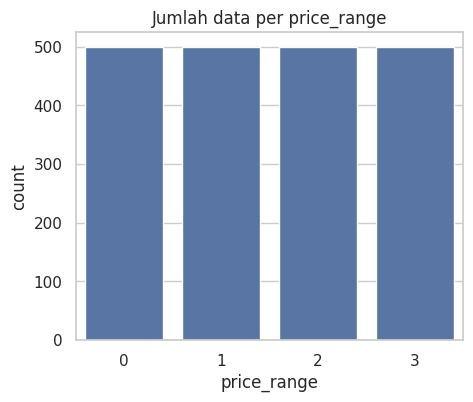

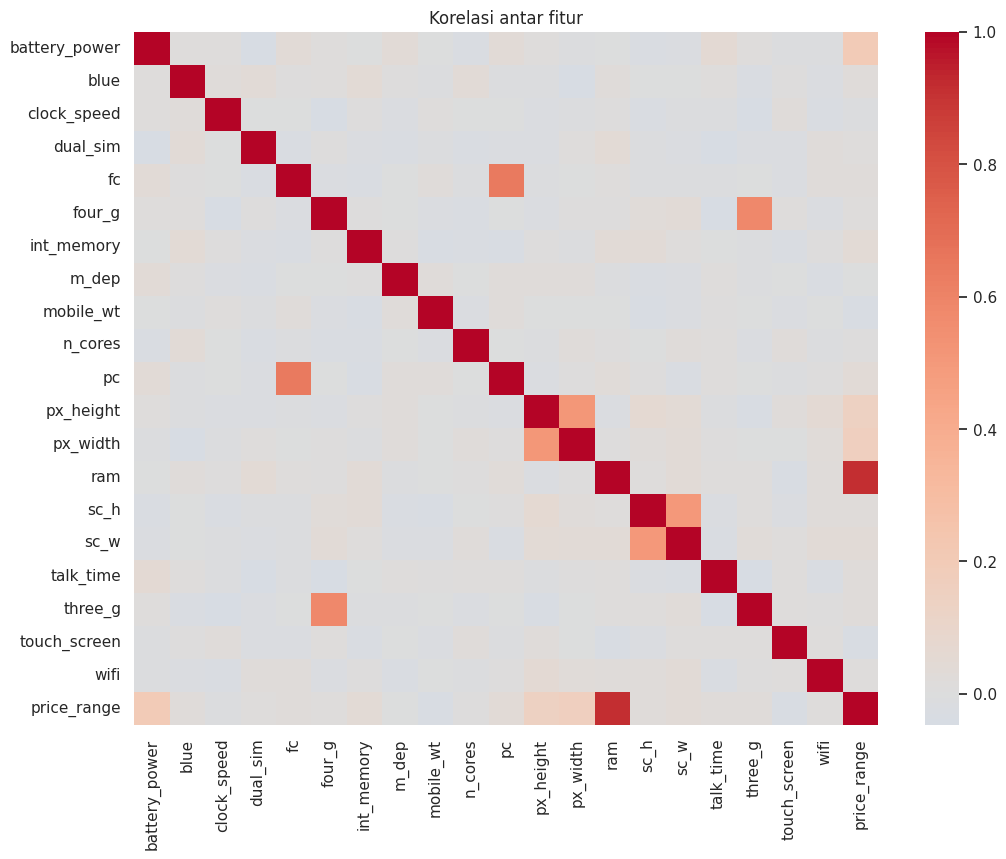

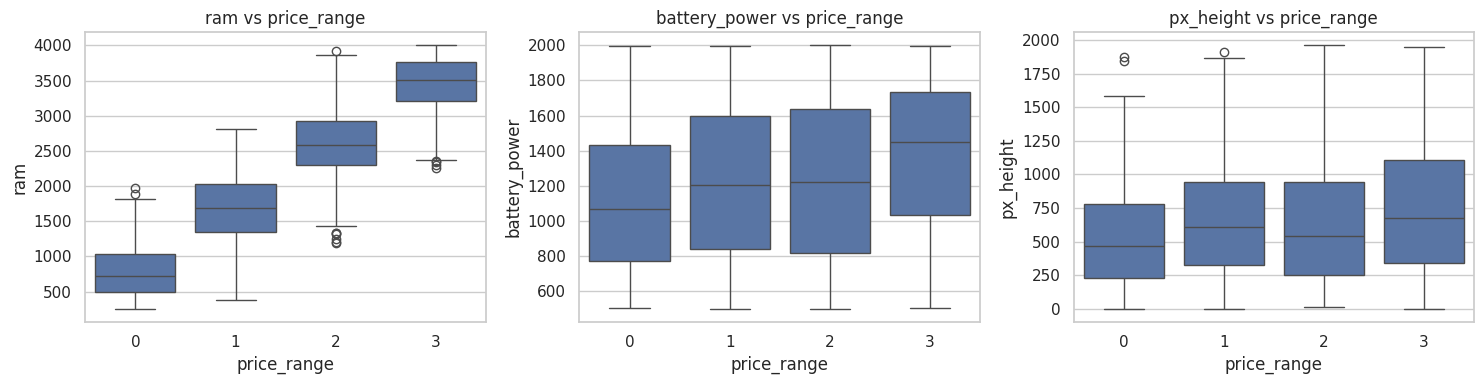

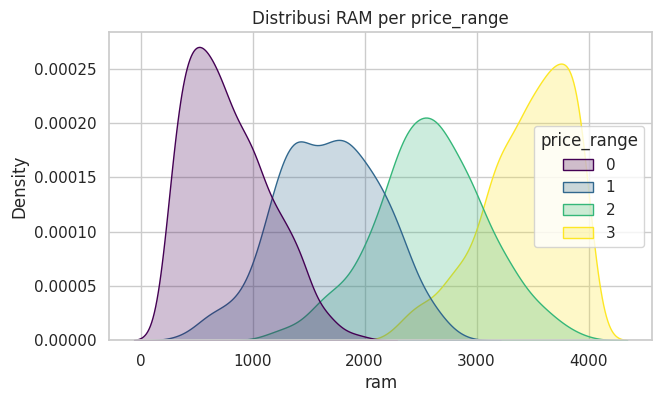

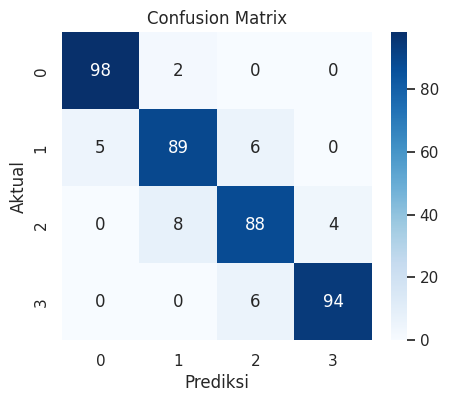

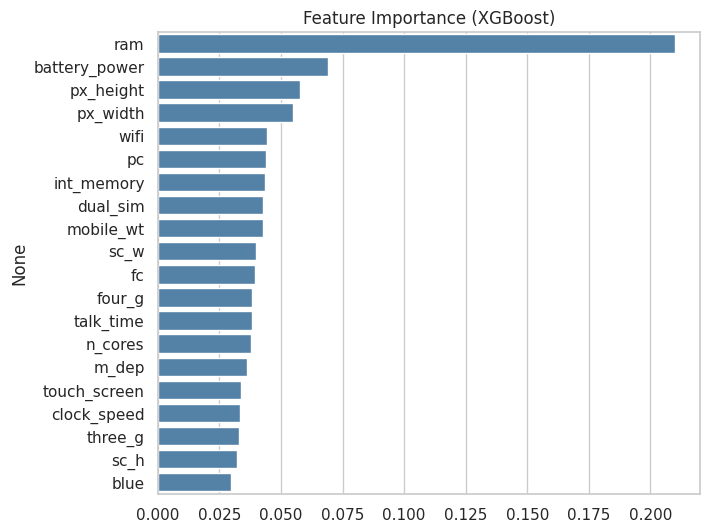

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid")

# 1. Distribusi target
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="price_range")
plt.title("Jumlah data per price_range")
plt.show()

# 2. Heatmap korelasi
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur")
plt.show()

# 3. Boxplot fitur penting vs target
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["ram", "battery_power", "px_height"]):
    sns.boxplot(data=df, x="price_range", y=col, ax=ax)
    ax.set_title(f"{col} vs price_range")
plt.tight_layout()
plt.show()

# 4. Distribusi RAM per kelas
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df, x="ram", hue="price_range", fill=True, palette="viridis")
plt.title("Distribusi RAM per price_range")
plt.show()

# 5. Confusion matrix (butuh model sudah fit)
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix")
plt.show()

# 6. Feature importance (butuh model sudah fit)
imp = pd.Series(
    model.best_estimator_.named_steps["algo"].feature_importances_,
    index=num_cols
).sort_values(ascending=False)

plt.figure(figsize=(7, 6))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Feature Importance (XGBoost)")
plt.show()